# Reconocimiento facial

**Institución:** Instituto Tecnológico de Culiacán  
**Carrera:** Ingeniería en Sistemas Computacionales  

**Integrantes del equipo:**
* Ángel Gabriel Muñoz Vega
* María Fernanda Valenzuela Soto

##Parte 1: Preparación del entorno

Importar librerias y verifica en pantalla las versiones instaladas de TensorFlow y OpenCV

In [ ]:
import os, json, base64
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)

TensorFlow: 2.21.0
OpenCV: 4.14.0


##1. Conexión a la nube
Conectamos Google Colab con una cuenta de Google Drive para poder leer los archivos desde la nube. Luego, se definen las rutas donde están guardadas las carpetas con las fotos de cada persona (DATASET_DIR), la ruta donde se guardarán los modelos entrenados (SALIDA_DIR), el tamaño de lote (BATCH_SIZE = 32), y finalmente revisa la carpeta principal para imprimir en orden alfabético los nombres de todas las carpetas (personas/clases) detectadas.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATASET_DIR = "/content/drive/MyDrive/Colab Notebooks/ProyectoReconocimientoFacial/Dataset"
SALIDA_DIR = "/content/drive/MyDrive/Colab Notebooks/Proyecto rostros/Modelos"
BATCH_SIZE = 32

print("Personas encontradas:", sorted(d for d in os.listdir(DATASET_DIR)
                                      if os.path.isdir(os.path.join(DATASET_DIR, d))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Personas encontradas: ['Angel', 'Brad Pitt', 'Hugh Jackman', 'Jennifer Lawrence', 'Leonardo DiCaprio', 'Maria', 'Megan Fox', 'Robert Downey Jr']


## 2. Carga, Redimensionamiento y Extracción del Dataset
En esta celda se procesan las imágenes almacenadas en Drive para convertirlas en matrices numéricas operables por la red neuronal:
* **Estandarización de formato:** Todas las fotografías se redimensionan a **$160 \times 160$ píxeles** manteniendo sus **3 canales de color (RGB)** (`color_mode="rgb"`).
* **Etiquetado y mezclado automático:** TensorFlow asigna un índice numérico a cada persona según el nombre de su carpeta y mezcla las imágenes aleatoriamente (`shuffle=True`) para evitar sesgos durante el aprendizaje.
* **Conversión a NumPy:** Finalmente, se extraen las imágenes y sus respectivas etiquetas de los lotes (*batches*) y se unifican en dos arreglos globales: **`x`** (matriz de imágenes) y **`y`** (vector de etiquetas).

In [ ]:
TAM = 160
BATCH_SIZE = 32

ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    color_mode="rgb",
    image_size=(TAM, TAM),
    batch_size=BATCH_SIZE,
    shuffle=True
)

nombres = ds.class_names

x, y = [], []
for imgs, labs in ds:
    x.append(imgs.numpy())
    y.append(labs.numpy())
x = np.concatenate(x)
y = np.concatenate(y)
print("Clases:", nombres)

Found 2525 files belonging to 8 classes.
Clases: ['Angel', 'Brad Pitt', 'Hugh Jackman', 'Jennifer Lawrence', 'Leonardo DiCaprio', 'Maria', 'Megan Fox', 'Robert Downey Jr']


## 3. Visualización y Verificación de Muestras del Dataset
Antes de entrenar el modelo, se despliega una cuadrícula de **$3 \times 3$** con 9 imágenes tomadas del primer lote del dataset junto con el nombre de su clase asignada. Esta inspección visual permite confirmar que las fotografías se cargaron sin distorsiones y que las etiquetas corresponden correctamente a cada persona.

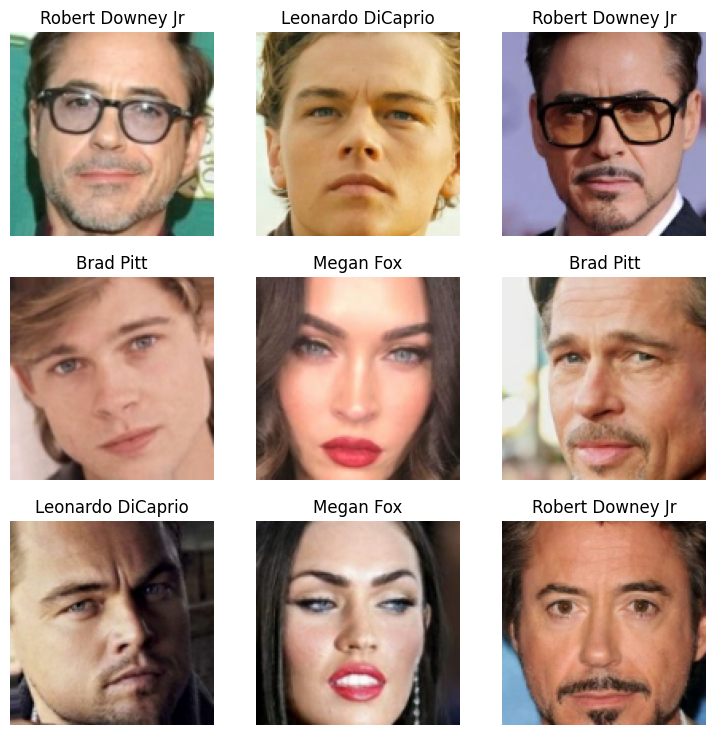

In [ ]:
plt.figure(figsize=(9, 9))
for imgs, labs in ds.take(1):
    for i in range(min(9, len(imgs))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].numpy().squeeze().astype("uint8"), cmap="gray")
        plt.title(nombres[labs[i]])
        plt.axis("off")
plt.show()

## 4. Preparación del Dataset
En esta celda se cargan nuevamente las imágenes ajustando su resolución a **$160 \times 160$ píxeles** en formato a color (**RGB**), dimensión requerida por la arquitectura **MobileNetV2**. Se establece `shuffle=False` para mantener un orden determinista en la extracción hacia los arreglos `x` e `y`, delegando la mezcla aleatoria de forma controlada a la etapa posterior de división (`train_test_split`).

In [ ]:
ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, color_mode="rgb", image_size=(160, 160),
    batch_size=BATCH_SIZE, shuffle=False)

nombres = ds.class_names

x, y = [], []
for imgs, labs in ds:
    x.append(imgs.numpy())
    y.append(labs.numpy())
x = np.concatenate(x)
y = np.concatenate(y)

print("Clases:", nombres)

Found 2525 files belonging to 8 classes.
Clases: ['Angel', 'Brad Pitt', 'Hugh Jackman', 'Jennifer Lawrence', 'Leonardo DiCaprio', 'Maria', 'Megan Fox', 'Robert Downey Jr']


## 5. Normalización y Prueba
En esta etapa se preparan las matrices de entrada antes del entrenamiento:
* **Normalización:** Se convierten los valores de los píxeles a punto flotante (`float32`) y se dividen entre `255.0` para escalarlos al intervalo $[0, 1]$, acelerando la convergencia del modelo.
* **Prueba:** Se separa el conjunto de datos en **80% para entrenamiento** (`x_train`, `y_train`) y **20% para evaluación** (`x_test`, `y_test`) mediante muestreo estratificado (`stratify=y`), asegurando que todas las clases conserven la misma proporción en ambos grupos.

In [ ]:
x = x.astype('float32') / 255.0

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (2020, 160, 160, 3)
Target matrix (y_train): (2020,)
Feature matrix (x_test): (505, 160, 160, 3)
Target matrix (y_test): (505,)


### 6. Creación y Compilación de la Red Neuronal
En este bloque se arma la estructura del modelo y se configura su entrenamiento:
* **Entrada (`Flatten`):** Convierte cada foto a color ($160 \times 160 \times 3$) en una sola lista larga de números para que la red pueda leerla.
* **Capas ocultas (`Dense`):** Dos capas internas de $256$ y $128$ neuronas que aprenden los patrones de cada rostro.
* **Salida (`Softmax`):** Calcula la probabilidad de a qué persona pertenece la foto.
* **Compilación:** Configura el optimizador (`adam`) y la métrica de aciertos (`accuracy`) para empezar a entrenar.

In [ ]:
model = Sequential([
    Flatten(input_shape=(160, 160, 3)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(len(nombres), activation='softmax'),
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 7. Entrenamiento y Evaluación del Modelo
En este bloque se entrena la red neuronal durante **20 épocas** (vueltas completas a los datos) en grupos de 32 imágenes, reservando el 20% para ir validando su avance en cada época. Al finalizar, se evalúa el modelo con las fotos de prueba (`x_test`) que nunca había visto para obtener su calificación real de pérdida y exactitud.

In [ ]:
mode = model.fit(x_train, y_train, epochs=20,
          batch_size=32,
          validation_split=0.2)
results = model.evaluate(x_test, y_test, verbose=0)
print('Test loss, Test accuracy:', results)

Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.2679 - loss: 15.5706 - val_accuracy: 0.2599 - val_loss: 4.7070
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.4827 - loss: 2.5132 - val_accuracy: 0.6609 - val_loss: 1.0816
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6386 - loss: 1.3071 - val_accuracy: 0.7079 - val_loss: 1.1372
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6757 - loss: 1.0768 - val_accuracy: 0.7673 - val_loss: 0.7290
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7333 - loss: 0.8095 - val_accuracy: 0.7030 - val_loss: 0.9477
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7543 - loss: 0.7763 - val_accuracy: 0.7946 - val_loss: 0.5867
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7642 - loss: 0.7065 - val_accuracy: 0.6188 - val_loss: 1.2845
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7593 - loss: 0.7942 - val_accuracy: 0.8020 - 

## 8. Gráficas de Rendimiento del Entrenamiento
En esta última celda se dibujan dos gráficas comparativas a partir del historial guardado en `mode`:
* **Accuracy (Izquierda):** Muestra qué tanto subieron los aciertos del modelo en entrenamiento (azul) y validación (naranja) en cada época.
* **Loss (Derecha):** Muestra cómo fue bajando el error del modelo conforme avanzó el entrenamiento.

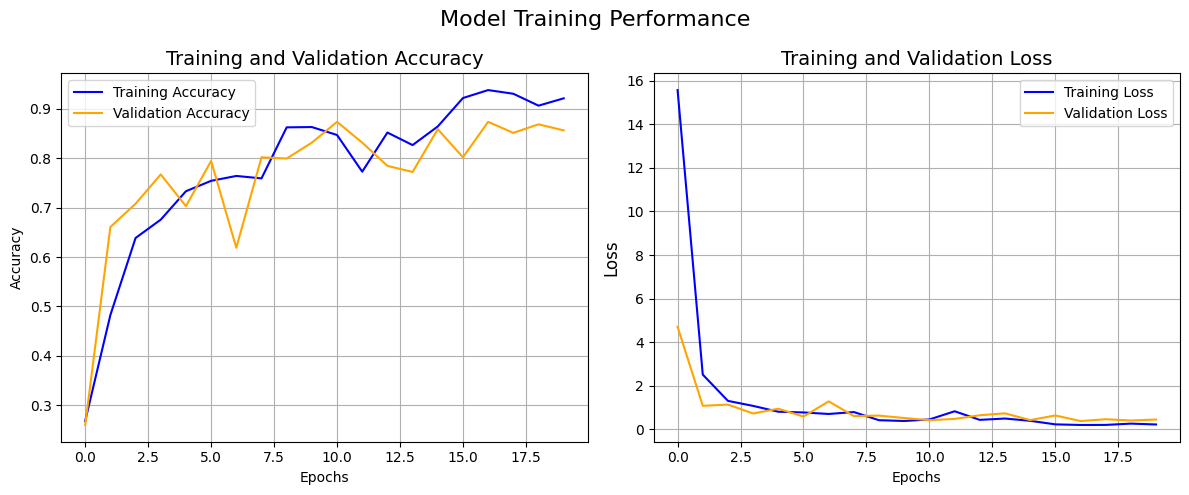

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mode.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mode.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(mode.history['loss'], label='Training Loss', color='blue')
plt.plot(mode.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

## 9. Guardado del Modelo y Etiquetas de Clases
En esta celda se exportan los resultados del entrenamiento al Drive para reutilizar el sistema más adelante sin tener que reentrenarlo:
* **`modelo_caras.keras`:** Archivo que almacena la estructura y los pesos aprendidos por la red neuronal.
* **`clases.json`:** Archivo de texto que guarda los nombres de cada persona en el orden exacto que les asignó el modelo.

In [ ]:
os.makedirs(SALIDA_DIR, exist_ok=True)
model.save(os.path.join(SALIDA_DIR, "modelo_caras.keras"))
with open(os.path.join(SALIDA_DIR, "clases.json"), "w", encoding="utf-8") as f:
    json.dump(nombres, f, ensure_ascii=False)
print("Guardado en:", SALIDA_DIR)

Guardado en: /content/drive/MyDrive/Colab Notebooks/Proyecto rostros/Modelos


## 10. Detección y Preprocesamiento de Rostros en Tiempo Real
En esta celda se carga el detector facial de OpenCV y se definen las funciones que preparan una imagen nueva antes de enviarla al modelo:
* **`detector`:** Carga el modelo *Haar Cascade* de OpenCV para localizar automáticamente dónde hay un rostro en la foto o cámara.
* **`recortar`:** Extrae el rostro detectado añadiendo un margen del 25% alrededor para no cortar facciones y lo ajusta a un cuadrado de $160 \times 160$ píxeles.
* **`preparar`:** Cambia el formato de color de BGR (OpenCV) a RGB y normaliza los píxeles dividiendo entre `255.0` para que coincidan con el entrenamiento.

In [ ]:
detector = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
assert not detector.empty(), "No se pudo cargar el detector (¿OpenCV 5? usa opencv-python<5)."

def recortar(frame, caja, margen=0.25, lado_final=160):
    x0, y0, w, h = caja
    lado = int(max(w, h) * (1 + margen))
    cx, cy = x0 + w // 2, y0 + h // 2
    x1, y1 = max(cx - lado // 2, 0), max(cy - lado // 2, 0)
    x2, y2 = min(x1 + lado, frame.shape[1]), min(y1 + lado, frame.shape[0])
    return cv2.resize(frame[y1:y2, x1:x2], (lado_final, lado_final), interpolation=cv2.INTER_AREA)

def preparar(cara):
    rgb = cv2.cvtColor(cara, cv2.COLOR_BGR2RGB).astype('float32')
    rgb = tf.image.resize(rgb, (160, 160)).numpy()
    return rgb / 255.0

## 11. Función de Predicción en Tiempo Real (Conexión Python – Navegador)
En este bloque se define la función que procesa cada fotograma enviado desde la cámara web del navegador:
* **Recepción y detección:** Decodifica la imagen recibida desde JavaScript, ajusta su iluminación en escala de grises y localiza los rostros presentes.
* **Clasificación con umbral:** Cada rostro recortado pasa por la red neuronal; si la confianza supera el **70%** (`UMBRAL = 0.70`), muestra el nombre de la persona, y si es menor, lo marca como **"Desconocido"**.
* **Registro en Colab:** Con `output.register_callback`, esta función queda disponible para ser llamada en vivo desde la interfaz de la cámara.

In [ ]:
from IPython.display import display, HTML, JSON, Javascript
from google.colab import output

UMBRAL = 0.70     # por debajo de esta confianza se muestra "Desconocido"

def predecir_frame(data_url):
    try:
        datos = base64.b64decode(data_url.split(",")[1])
        frame = cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)
        gris = cv2.equalizeHist(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
        caras = detector.detectMultiScale(gris, 1.1, 6, minSize=(60, 60))
        resultados = []
        for (x0, y0, w, h) in caras:
            p = model(preparar(recortar(frame, (x0, y0, w, h)))[None], training=False).numpy()[0]
            nombre = nombres[p.argmax()] if p.max() >= UMBRAL else "Desconocido"
            resultados.append({"x": int(x0), "y": int(y0), "w": int(w), "h": int(h),
                               "nombre": nombre, "conf": round(float(p.max()), 3)})
        return JSON({"caras": resultados})
    except Exception as e:
        return JSON({"error": str(e)})

output.register_callback("predecir_frame", predecir_frame)

## 12. Interfaz de Cámara Web y Reconocimiento en Vivo
En esta última celda se crea la interfaz visual en HTML y JavaScript dentro de Colab para probar el sistema en tiempo real:
* **Acceso a la cámara:** Solicita permisos al navegador y muestra el video en vivo junto con un botón para detener la captura.
* **Envío de fotogramas:** Toma capturas periódicas del video y las envía a la función `predecir_frame` de Python.
* **Visualización de resultados:** Dibuja sobre cada rostro un recuadro **verde** (persona identificada) o **naranja** (desconocido) con su nombre, porcentaje de confianza y velocidad en FPS.

In [ ]:
display(HTML("""
<div style="position:relative; width:480px; font-family:sans-serif">
  <video id="video" autoplay playsinline muted style="width:480px; border-radius:8px; background:#000"></video>
  <canvas id="overlay" style="position:absolute; left:0; top:0"></canvas>
  <div style="margin-top:8px">
    <button id="detener" style="padding:6px 14px">Detener cámara</button>
    <span id="info" style="margin-left:10px">Iniciando cámara…</span>
  </div>
</div>
"""))

display(Javascript("""
(async () => {
  const video = document.getElementById('video');
  const overlay = document.getElementById('overlay');
  const info = document.getElementById('info');
  const boton = document.getElementById('detener');

  let stream;
  try {
    stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
  } catch (e) {
    info.textContent = 'No se pudo acceder a la cámara: ' + e.message;
    return;
  }
  video.srcObject = stream;
  await new Promise(r => video.onloadedmetadata = r);

  const W = 480, H = Math.round(480 * video.videoHeight / video.videoWidth);
  overlay.width = W; overlay.height = H;
  const captura = document.createElement('canvas');
  captura.width = W; captura.height = H;
  const cctx = captura.getContext('2d');
  const octx = overlay.getContext('2d');

  let activo = true;
  boton.onclick = () => {
    activo = false;
    stream.getTracks().forEach(t => t.stop());
    octx.clearRect(0, 0, W, H);
    info.textContent = 'Cámara detenida';
  };

  while (activo) {
    const t0 = performance.now();
    cctx.drawImage(video, 0, 0, W, H);
    const url = captura.toDataURL('image/jpeg', 0.8);
    try {
      const r = await google.colab.kernel.invokeFunction('predecir_frame', [url], {});
      const res = r.data['application/json'];
      octx.clearRect(0, 0, W, H);
      if (res.error) {
        info.textContent = 'Error: ' + res.error;
      } else {
        for (const c of res.caras) {
          const conocido = c.nombre !== 'Desconocido';
          const color = conocido ? '#22c55e' : '#f59e0b';
          octx.lineWidth = 3; octx.strokeStyle = color;
          octx.strokeRect(c.x, c.y, c.w, c.h);
          const texto = c.nombre + ' (' + Math.round(c.conf * 100) + '%)';
          octx.font = 'bold 16px sans-serif';
          const tw = octx.measureText(texto).width + 10;
          octx.fillStyle = color;
          octx.fillRect(c.x, Math.max(c.y - 24, 0), tw, 24);
          octx.fillStyle = '#000';
          octx.fillText(texto, c.x + 5, Math.max(c.y - 7, 17));
        }
        const fps = 1000 / (performance.now() - t0);
        info.textContent = res.caras.length + ' cara(s) · ' + fps.toFixed(1) + ' fps';
      }
    } catch (e) {
      info.textContent = 'Error de conexión con Python: ' + e;
      break;
    }
    await new Promise(r => setTimeout(r, 50));
  }
})();
"""))

<IPython.core.display.Javascript object>